# Synthetic Datasets for Predictive Maintenance

Companion notebook for the [SimWeave blog post](https://notabot123.github.io/simweave/blog/predictive-maintenance/).

This notebook covers:
- **Healthy baseline** — ThermalRC motor winding at steady state
- **Three fault profiles** — linear, exponential, and abrupt degradation
- **FaultDataset** — features, health index, RUL, failure mode labels
- **Multi-mode corpus** — stacking scenarios with `FaultDataset.concat`
- **Monte Carlo corpus** — 100 varied runs via `run_monte_carlo`
- **ML pipeline sketch** — DataFrame export and NumPy arrays for PyTorch/Keras
- **PNG export** — signal plots and health index charts for Medium

In [1]:
# Uncomment to install if running outside Binder
# !pip install 'simweave[viz,ml]>=0.8.1' kaleido

import numpy as np
import simweave as sw
from simweave.continuous.solver import simulate
from simweave.faults import FaultInjector, FaultProfile, ParameterFault, FaultDataset
from simweave.mc import run_monte_carlo
import plotly.graph_objects as go
import pathlib

IMG_DIR = pathlib.Path('img')
IMG_DIR.mkdir(exist_ok=True)

# Simulation parameters
AMBIENT  = 293.15   # 20 °C in Kelvin
Q_IN     = 50.0     # constant heat input (W)
DT       = 0.5      # integration step (s)
T_SPAN   = (0.0, 1200.0)  # 20-minute run
ONSET    = 400.0
FAILURE  = 1000.0

def fresh_system():
    return sw.ThermalRC(
        thermal_resistance=2.0,
        thermal_capacitance=800.0,
        ambient_temperature=AMBIENT,
        initial_temperature=AMBIENT,
    )

def constant_heat(t):
    return Q_IN

print('SimWeave', sw.__version__)
print(f'Healthy steady-state: {Q_IN * 2.0:.0f} K above ambient')

SimWeave 0.8.1
Healthy steady-state: 100 K above ambient


## 1  Healthy Baseline

In [2]:
healthy_inj    = FaultInjector(system=fresh_system(), faults=[])
healthy_result = simulate(healthy_inj, T_SPAN, dt=DT, inputs=constant_heat)
healthy_ds     = FaultDataset.from_result(
    healthy_result, healthy_inj, noise_std=0.3, rng=np.random.default_rng(10)
)
print(healthy_ds)

FaultDataset(n=2401, features=['temperature', 'u0'], modes=['healthy'], failed=0)


## 2  Three Degradation Profiles

All three faults degrade `R_th` (thermal resistance), causing the winding to overheat.
The profiles differ only in *how* the resistance grows over time.

In [3]:
def run_fault(shape, mode_label, seed, max_delta=3.0, noise=0.3):
    '''Simulate one fault scenario; return (SimulationResult, FaultInjector, FaultDataset).'''
    profile  = FaultProfile(ONSET, FAILURE, mode=mode_label, shape=shape)
    fault    = ParameterFault('R_th', profile, max_delta=max_delta, relative=True)
    injector = FaultInjector(system=fresh_system(), faults=[fault])
    result   = simulate(injector, T_SPAN, dt=DT, inputs=constant_heat)
    ds       = FaultDataset.from_result(
        result, injector, noise_std=noise, rng=np.random.default_rng(seed)
    )
    return result, injector, ds


linear_result, linear_inj, linear_ds  = run_fault('linear',      'insulation_linear',      seed=20,
                                                    max_delta=3.0)
# Exponential faults are silent for longer but more severe at failure — use a higher
# max_delta so the late-stage temperature spike is visually distinct from linear.
exp_result,    exp_inj,    exp_ds     = run_fault('exponential',  'insulation_exponential', seed=30,
                                                    max_delta=5.0)
abrupt_result, abrupt_inj, abrupt_ds  = run_fault('abrupt',       'thermal_runaway',        seed=40,
                                                    max_delta=3.0)

for name, ds in [('healthy', healthy_ds), ('linear', linear_ds),
                 ('exponential', exp_ds), ('abrupt', abrupt_ds)]:
    print(f'{name:15s}  samples={len(ds):5d}  failed={ds.is_failed.sum():4d}')

healthy          samples= 2401  failed=   0
linear           samples= 2401  failed= 401
exponential      samples= 2401  failed= 401
abrupt           samples= 2401  failed=1601


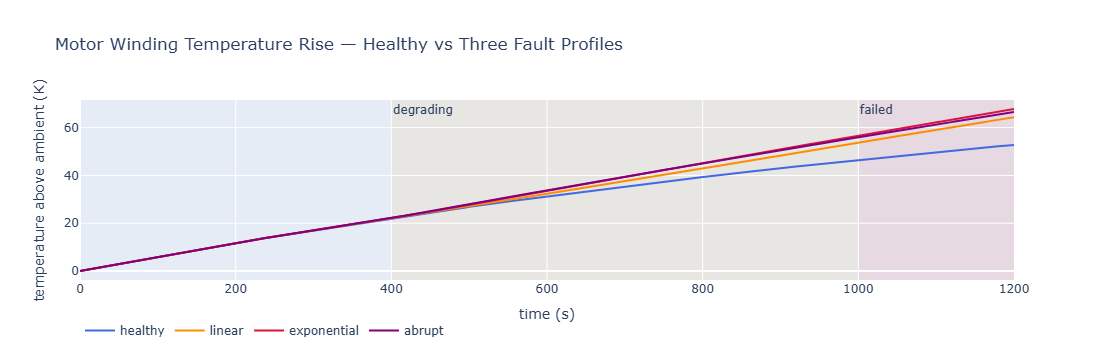

In [4]:
# Temperature signals — all four scenarios
fig_sig = go.Figure()
for result, label, color in [
    (healthy_result, 'healthy',     'royalblue'),
    (linear_result,  'linear',      'darkorange'),
    (exp_result,     'exponential', 'crimson'),
    (abrupt_result,  'abrupt',      'purple'),
]:
    fig_sig.add_trace(go.Scatter(
        x=result.time,
        y=result.state[:, 0] - AMBIENT,
        mode='lines', name=label, line={'color': color},
    ))
fig_sig.add_vrect(x0=ONSET,   x1=FAILURE,   fillcolor='orange', opacity=0.08,
                  layer='below', line_width=0,
                  annotation_text='degrading', annotation_position='top left')
fig_sig.add_vrect(x0=FAILURE, x1=T_SPAN[1], fillcolor='red',    opacity=0.08,
                  layer='below', line_width=0,
                  annotation_text='failed',    annotation_position='top left')
fig_sig.update_layout(
    title='Motor Winding Temperature Rise — Healthy vs Three Fault Profiles',
    xaxis_title='time (s)',
    yaxis_title='temperature above ambient (K)',
    legend={'orientation': 'h', 'y': -0.2},
)
fig_sig.show()
fig_sig.write_image(str(IMG_DIR / 'pdm_temperature_signals.png'), width=1100, height=500, scale=2)

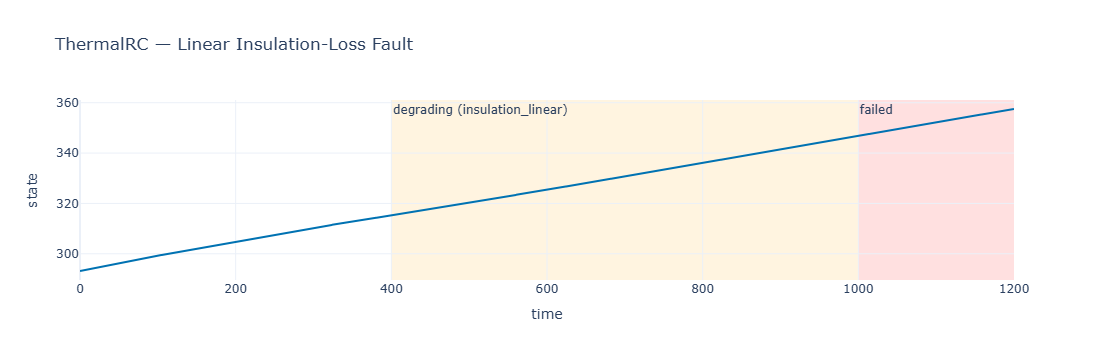

In [5]:
# plot_fault_signals — annotated view for linear fault
fig_fault = sw.plot_fault_signals(
    linear_result, linear_inj,
    title='ThermalRC — Linear Insulation-Loss Fault',
)
fig_fault.show()
fig_fault.write_image(str(IMG_DIR / 'pdm_fault_signals_linear.png'), width=900, height=450, scale=2)

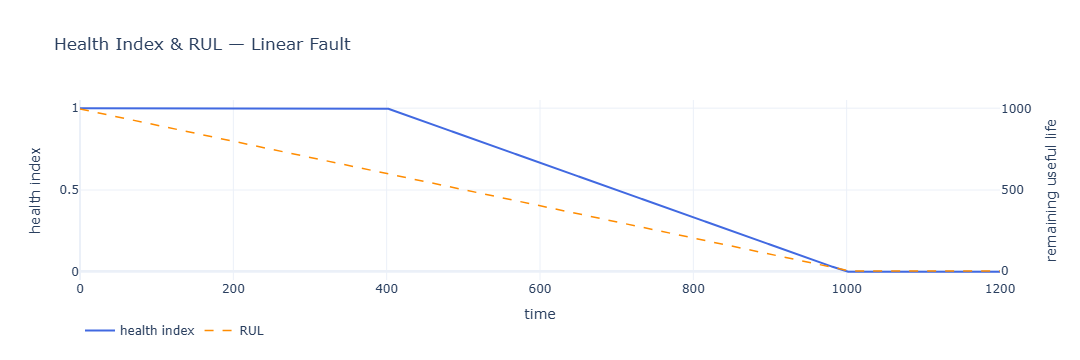

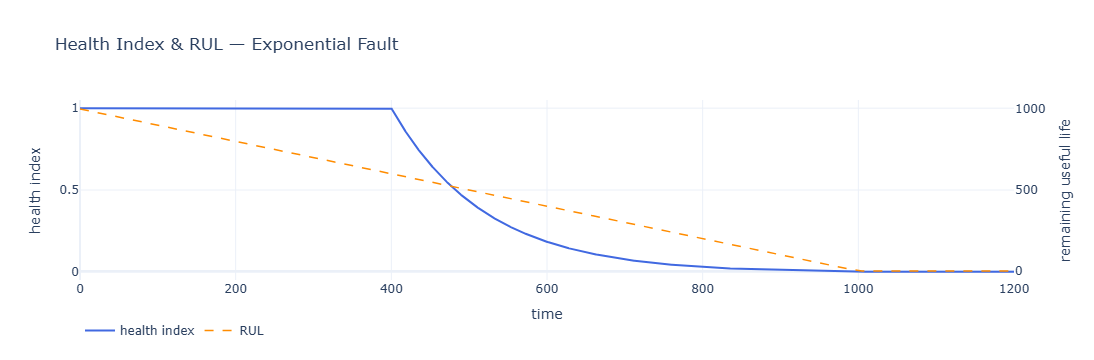

In [6]:
# Health index and RUL — linear vs exponential comparison
for ds, label, fname in [
    (linear_ds, 'Linear Fault',      'pdm_hi_linear.png'),
    (exp_ds,    'Exponential Fault',  'pdm_hi_exponential.png'),
]:
    fig_hi = sw.plot_health_index(ds, show_rul=True,
                                   title=f'Health Index & RUL — {label}')
    fig_hi.show()
    fig_hi.write_image(str(IMG_DIR / fname), width=900, height=450, scale=2)

## 3  Assembling a Multi-Mode Training Corpus

In [7]:
corpus = FaultDataset.concat([healthy_ds, linear_ds, exp_ds, abrupt_ds])
train_ds, test_ds = corpus.train_test_split(test_frac=0.2, rng=np.random.default_rng(99))

print(corpus)
print(f'Train : {len(train_ds):,} samples')
print(f'Test  : {len(test_ds):,} samples')
print(f'Features : {corpus.feature_names}')

FaultDataset(n=9604, features=['temperature', 'u0'], modes=['healthy', 'insulation_exponential', 'insulation_linear', 'thermal_runaway'], failed=2403)
Train : 7,683 samples
Test  : 1,921 samples
Features : ['temperature', 'u0']


In [8]:
# DataFrame summary (requires pandas)
try:
    df = corpus.to_dataframe()
    print('Class distribution:')
    print(df['failure_mode'].value_counts().to_string())
    # Filter out pre-onset samples where RUL is infinite
    finite_rul = df[np.isfinite(df['rul'])]
    print('\nRUL statistics by class (degrading + failed only):')
    print(finite_rul.groupby('failure_mode')['rul'].describe().round(1).to_string())
    print('\nFirst 5 rows:')
    print(df.head().to_string(index=False))
except ImportError:
    print('Install pandas for DataFrame output: pip install pandas')

Class distribution:
failure_mode
healthy                   4803
thermal_runaway           1601
insulation_linear         1600
insulation_exponential    1600

RUL statistics by class (degrading + failed only):
                         count   mean    std    min    25%    50%    75%     max
failure_mode                                                                    
healthy                 2402.0  800.1  115.6  600.0  700.0  800.0  900.0  1000.0
insulation_exponential  1600.0  224.8  198.4    0.0    0.0  199.8  399.6   599.5
insulation_linear       1600.0  224.8  198.4    0.0    0.0  199.8  399.6   599.5
thermal_runaway         1601.0  225.0  198.6    0.0    0.0  200.0  400.0   600.0

First 5 rows:
 time  temperature        u0  health_index  rul  is_failed failure_mode
  0.0   292.818998 49.782493           1.0  inf      False      healthy
  0.5   292.946704 50.080093           1.0  inf      False      healthy
  1.0   293.137906 50.037945           1.0  inf      False      healthy
  

## 4  Monte Carlo Corpus — 100 Varied Runs

Randomise onset time, fault severity, degradation shape, and sensor noise
to generate a statistically diverse training corpus.

In [9]:
def random_scenario(seed: int) -> FaultDataset:
    rng     = np.random.default_rng(seed)
    onset   = float(rng.uniform(200, 600))
    failure = onset + float(rng.uniform(300, 600))
    max_dR  = float(rng.uniform(1.0, 5.0))
    noise   = float(rng.uniform(0.1, 0.8))
    shape   = rng.choice(['linear', 'exponential'])

    t_end    = failure + 200.0
    profile  = FaultProfile(onset, failure, mode=f'insulation_{shape}', shape=shape)
    fault    = ParameterFault('R_th', profile, max_delta=max_dR, relative=True)
    injector = FaultInjector(system=fresh_system(), faults=[fault])
    result   = simulate(injector, (0.0, t_end), dt=DT, inputs=constant_heat)
    return FaultDataset.from_result(
        result, injector, noise_std=noise, rng=np.random.default_rng(seed + 1)
    )


print('Generating MC corpus (100 runs) ...')
mc = run_monte_carlo(random_scenario, n_runs=100, seeds=range(100), executor='threads')

big_corpus = FaultDataset.concat(list(mc.samples))
print(f'Total samples : {len(big_corpus):,}')
print(f'Failure modes : {set(big_corpus.failure_mode.tolist())}')

Generating MC corpus (100 runs) ...
Total samples : 215,645
Failure modes : {'insulation_exponential', 'healthy', 'insulation_linear'}


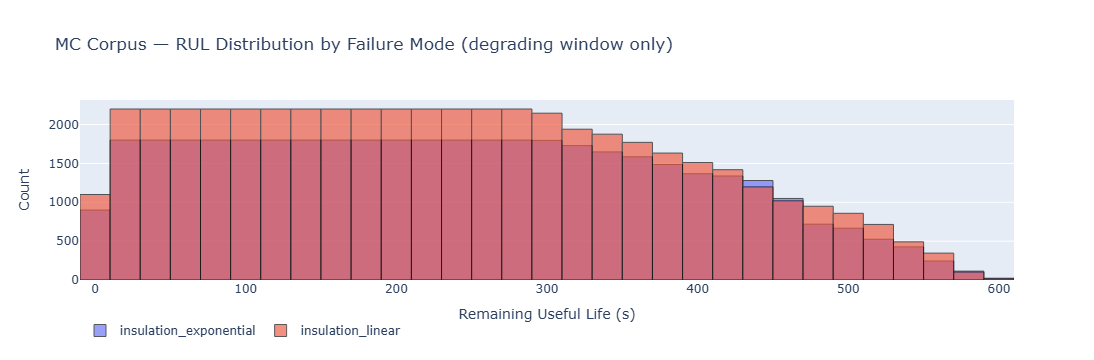

In [10]:
# Show the degrading window only — exclude failed samples (RUL=0) which otherwise
# dominate the histogram and make linear vs exponential indistinguishable.
rul_clipped    = big_corpus.rul.clip(0, 800)
degrading_mask = (
    np.isfinite(rul_clipped)
    & (rul_clipped > 0)                      # exclude failed window
    & (big_corpus.health_index < 1.0)        # exclude pre-onset healthy window
)

fig_rul = go.Figure()
for mode in sorted(set(big_corpus.failure_mode.tolist())):
    mask = (big_corpus.failure_mode == mode) & degrading_mask
    if mask.sum() == 0:
        continue
    fig_rul.add_trace(go.Histogram(
        x=rul_clipped[mask], nbinsx=40, name=mode, opacity=0.65,
        marker=dict(
                line=dict(
                    color='black',          # Edge (outline) color
                    width=1                 # Edge line width
                )
        )
    ))
fig_rul.update_layout(
    title='MC Corpus — RUL Distribution by Failure Mode (degrading window only)',
    xaxis_title='Remaining Useful Life (s)',
    yaxis_title='Count',
    barmode='overlay',
    legend={'orientation': 'h', 'y': -0.2},
)
fig_rul.show()
fig_rul.write_image(str(IMG_DIR / 'pdm_rul_distribution.png'), width=900, height=500, scale=2)

## 5  ML Pipeline — NumPy Arrays to PyTorch / Keras

The corpus arrays drop straight into standard training loops.

In [11]:
mc_train, mc_test = big_corpus.train_test_split(test_frac=0.2, rng=np.random.default_rng(0))

# --- RUL regression ---
# Mask to degrading + failed window only (healthy RUL is infinite)
degrading = mc_train.health_index < 1.0
X_reg = mc_train.features[degrading]           # (N_deg, F)
y_rul = mc_train.rul[degrading].clip(0, 800)   # (N_deg,)
print(f'Regression  — X shape: {X_reg.shape},  y shape: {y_rul.shape}')

# --- Fault classification ---
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
X_cls = mc_train.features                        # (N, F)
y_cls = le.fit_transform(mc_train.failure_mode)  # (N,) integer labels
print(f'Classification — X shape: {X_cls.shape},  classes: {le.classes_}')

# --- Binary health flag ---
y_bin = mc_train.is_failed.astype(int)           # 0=healthy, 1=failed
print(f'Binary detection — positive rate: {y_bin.mean():.1%}')

Regression  — X shape: (105126, 2),  y shape: (105126,)
Classification — X shape: (172516, 2),  classes: ['healthy' 'insulation_exponential' 'insulation_linear']
Binary detection — positive rate: 18.5%


In [12]:
# PyTorch LSTM for RUL regression — build model and train for 1 epoch
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import TensorDataset, DataLoader

    SEQ_LEN    = 30
    BATCH_SIZE = 64
    N_FEATURES = X_reg.shape[1]

    X_t = torch.tensor(X_reg, dtype=torch.float32)
    y_t = torch.tensor(y_rul, dtype=torch.float32)

    if len(X_t) <= SEQ_LEN:
        print('Corpus too small for sequence modelling — increase n_runs')
    else:
        # Sliding window: shape (N, SEQ_LEN, N_FEATURES)
        seqs    = X_t.unfold(0, SEQ_LEN, 1).permute(0, 2, 1)
        targets = y_t[SEQ_LEN - 1:]

        dataset    = TensorDataset(seqs, targets)
        loader     = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

        class RULPredictor(nn.Module):
            def __init__(self, n_feat, hidden=64):
                super().__init__()
                self.lstm   = nn.LSTM(n_feat, hidden, batch_first=True)
                self.linear = nn.Linear(hidden, 1)
            def forward(self, x):
                _, (h, _) = self.lstm(x)
                return self.linear(h[-1]).squeeze(-1)

        model     = RULPredictor(N_FEATURES)
        optimiser = torch.optim.Adam(model.parameters(), lr=1e-3)
        criterion = nn.MSELoss()

        # --- 1 epoch ---
        model.train()
        epoch_loss, n_batches = 0.0, 0
        for X_batch, y_batch in loader:
            optimiser.zero_grad()
            pred = model(X_batch)
            loss = criterion(pred, y_batch)
            loss.backward()
            optimiser.step()
            epoch_loss += loss.item()
            n_batches  += 1

        mean_rmse = (epoch_loss / n_batches) ** 0.5
        print(f'Epoch 1 complete — {n_batches} batches, mean RMSE: {mean_rmse:.1f} s')
        print(f'Input shape: {seqs.shape}  |  target shape: {targets.shape}')
        print('(1 epoch is illustrative — train for ~50+ epochs for convergence)')

except ImportError:
    print('PyTorch not installed — skipping LSTM sketch (pip install torch)')

Epoch 1 complete — 1643 batches, mean RMSE: 209.9 s
Input shape: torch.Size([105097, 30, 2])  |  target shape: torch.Size([105097])
(1 epoch is illustrative — train for ~50+ epochs for convergence)


## 6  Custom Degradation Profile

Any callable `f(progress) -> health ∈ [0, 1]` works as a shape.
Here we use a Weibull-CDF-shaped profile typical of infant-mortality + wearout systems.

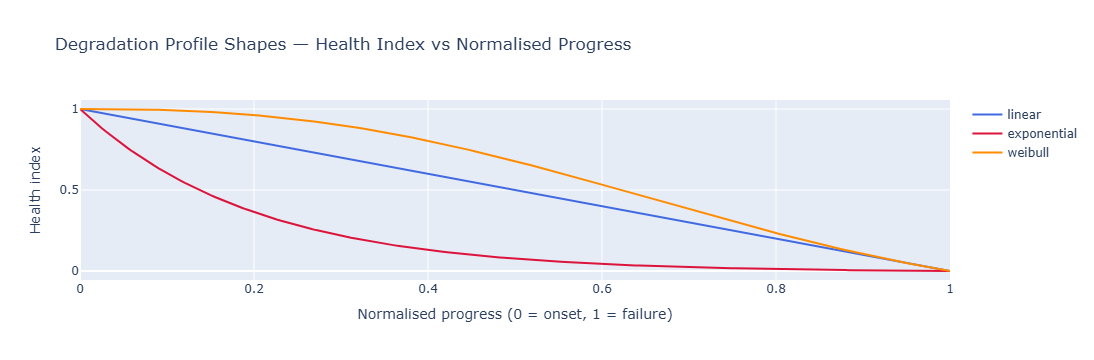

In [13]:
import math

def weibull_health(progress: float) -> float:
    '''Weibull survival function, normalised so health(0)=1 and health(1)=0 exactly.
    Without normalisation exp(-(p/λ)^k) evaluates to ~0.17 at p=1 for these parameters,
    which would leave the health index above zero at failure.'''
    k, lam = 2.5, 0.8
    raw   = math.exp(-(progress / lam) ** k)
    floor = math.exp(-(1.0   / lam) ** k)   # value at progress=1 without normalisation
    return (raw - floor) / (1.0 - floor)    # rescale: health(0)=1, health(1)=0

wb_result, wb_inj, wb_ds = run_fault(weibull_health, 'weibull_wear', seed=50)

# Compare Weibull vs linear vs exponential health trajectories
t_norm   = np.linspace(0, 1, 200)
h_linear = np.maximum(1.0 - t_norm, 0.0)
h_exp    = np.array([max(0.0, (math.exp(5*(1-p))-1)/(math.exp(5)-1)) for p in t_norm])
h_weib   = np.array([weibull_health(p) for p in t_norm])

fig_shapes = go.Figure()
for name, health, color in [
    ('linear',      h_linear, 'royalblue'),
    ('exponential', h_exp,    'crimson'),
    ('weibull',     h_weib,   'darkorange'),
]:
    fig_shapes.add_trace(go.Scatter(
        x=t_norm, y=health, mode='lines', name=name, line={'color': color},
    ))
fig_shapes.update_layout(
    title='Degradation Profile Shapes — Health Index vs Normalised Progress',
    xaxis_title='Normalised progress (0 = onset, 1 = failure)',
    yaxis_title='Health index',
)
fig_shapes.show()
fig_shapes.write_image(str(IMG_DIR / 'pdm_profile_shapes.png'), width=800, height=450, scale=2)

## Summary — Exported Images for Medium

| File | Description |
|---|---|
| `pdm_temperature_signals.png` | Healthy vs three fault profile temperature traces |
| `pdm_fault_signals_linear.png` | Annotated fault signal view (linear) |
| `pdm_hi_linear.png` | Health index and RUL — linear fault |
| `pdm_hi_exponential.png` | Health index and RUL — exponential fault |
| `pdm_rul_distribution.png` | RUL distribution across 100 MC corpus runs |
| `pdm_profile_shapes.png` | Shape comparison: linear / exponential / Weibull |